# ***CT5120: Introduction to NLP***

# ***Assignment 1: Hate Speech Classification*** (Total 100 marks)
This assignment is focused on Hate Speech Classification from social media comments.

---

###  **Student Details**

Enter your

**Name:** William Vida

**Student ID:** 22749181

---

>  <font color="red">**Disclaimer:** This assignment may contain hate speech and offensive content, strictly for academic purposes. </font>

---
 **Deadline:** **`01:45 PM, 09th October, 2026`** (Ireland Time)

 **Submission Format:** `.ipynb`

 **Individual Assignment:** This is an individual assignment - your work must be your own.

<!-- ---

###  Academic Integrity

<font color="red">**Strictly no Generative AI.**</font> Do the assignment by yourself - write code and answers fully in your own words, without using AI tools.

<font color="red">**Note:**</font> You must **disable the AI features on Google Colab** before working on this assignment.
 Guide: [How to disable AI in Colab](https://youtu.be/qrGZv8nPh1o) -->



---

###  **In-Lab Grading — "Defend Your Work!**"

Think of this as a **mini viva** — you built it, so you should be able to talk through it.

| | |
|---|---|
|  **When** | `September 25th`, `October 2nd` & `October 9th, 2026` [12:00 PM to 02:00 PM] |
|  **What** | A short, friendly Q&A with your TAs |
|  **How** | TAs will ask you a few questions about your notebook |

>  **Pro tip:** You don't need to memorise every line. If you understand *What, How, & Why* you made each decision, you'll breeze through this.

No surprises, no trick questions - just show us it's genuinely **your work, and your understanding.**



---

###  **Task Roadmap**

Here's what you'll be building, step by step:

| # | Section | Focus |
|---|---|---|
| 1️ | **Dataset & EDA** | Pick a dataset, justify it, explore the classes (One example provided ) |
| 2️ | **Training & Evaluation** | Train a classifier, evaluate it properly |
| 3️ | **Improve It** | Tune the *same* model, prove it got better |

Each section builds on the last - so a solid dataset and clean features in Sections 1 will make Sections 2-3 much smoother.

---

###  Important

<!-- -  Only edit cells marked `# YOUR CODE HERE` or `# YOUR ANSWER HERE` — leave everything else untouched. -->
-  Run **all cells top-to-bottom** with no errors before submitting.
-  **Google Colab** is recommended to avoid dependency issues.

---

---
# **Dataset Details**

The dataset can be divided into **three parts**: **Training**, **Development (Dev)**, and **Test** sets.  

1. **Training set**  
   - Used to **train your model** (learn patterns from the data).  
   - This is the largest portion of the dataset.  

2. **Development (Dev) set**  
   - A small part of the training data that is **held out**.  
   - Used to **validate your model** while training and for **hyperparameter tuning**.  
   - Helps avoid overfitting (your model performing well on training but poorly on unseen data).  

3. **Test set**  
   - Contains **unlabeled data** (labels are hidden).
   - Used only for **final evaluation** of your model.  
   - You will generate a **prediction file** for this set and submit it.  

---

# Installing and Importing Packages

> **Note:** This setup cell is not directly graded. You may install and import any Python packages required for your experiments.  
> Commonly used libraries for this assignment may include `pandas`, `numpy`, `matplotlib`, `scikit-learn`, and relevant NLP libraries.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

---

# **Section 1: Dataset Selection & Exploratory Data Analysis**

### `Total = 30 marks`

Before building your classification model, select a suitable **hate-speech classification dataset** and explore its main characteristics.

> **Note:** You may use one of the example datasets provided in Task 1a, or select another appropriate publicly available dataset.

| Task | What you'll do | Marks |
|---|---|---|
| **1a** | Select and load a dataset, and prepare Train / Dev / Test splits | `5` |
| **1b** | Plot the **class distribution** using a suitable visualisation | `10` |
| **1c** | Carry out **Exploratory Data Analysis (EDA)** relevant to your dataset, such as text length, vocabulary size, common n-grams, or other informative characteristics | `5` |
| **1d** | Explain your **dataset selection** and the main findings from your EDA | `10` |

> A clear understanding of the dataset will help you make better decisions in the later modelling and evaluation sections.

---

## **1a: Dataset** (5 marks)

Select and load **one suitable hate-speech classification dataset** for this assignment.

> **Note:** You may choose **one of the example datasets listed below**, or you may use **another appropriate publicly available dataset** of your choice.

Example datasets:

1. https://huggingface.co/datasets/christinacdl/binary_hate_speech  
2. https://huggingface.co/datasets/tdavidson/hate_speech_offensive  
3. https://huggingface.co/datasets/tweets-hate-speech-detection/tweets_hate_speech_detection  
4. https://huggingface.co/datasets/badmatr11x/hate-offensive-speech  

If you choose a different dataset, it should contain:

- textual input data;
- clearly defined class labels;
- enough examples for model training and evaluation.

Use the dataset's existing **Train / Dev / Test splits** where available. If suitable splits are not provided, create them yourself.

Tutorial: [Loading a dataset from Hugging Face](https://huggingface.co/docs/datasets/load_hub)

In [2]:
# Load the train, validation, and test splits of the dataset.
base = "hf://datasets/badmatr11x/hate-offensive-speech/"
splits = {
    "train": "data/train-00000-of-00001-b57a122b095e5ed1.parquet",
    "validation": "data/validation-00000-of-00001-9ea89a9fc1c6b387.parquet",
    "test": "data/test-00000-of-00001-10d11e25d2e9ec6e.parquet",
}
df_train = pd.read_parquet(base + splits["train"])
df_validation = pd.read_parquet(base + splits["validation"])
df_test = pd.read_parquet(base + splits["test"])

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## **1b: Class Distribution** (10 marks)

Index(['label', 'tweet'], dtype='str')
Label values: [2 1 0]

{
  "label": {
    0: "hate-speech",
    1: "offensive-speech",
    2: "neither"
  },
  "tweet": <string>
}

       count  percentage
label                   
0       3294    6.449971
1      17256   33.788917
2      30520   59.761112


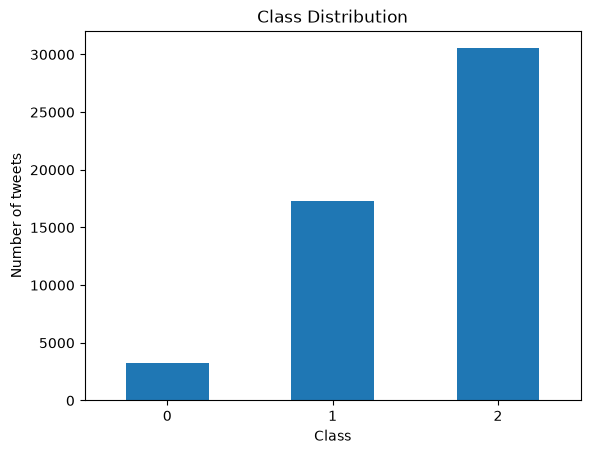

In [3]:
# Information about the data.
print(df_train.columns)
print("Label values:", df_train["label"].unique())

class_counts = df_train["label"].value_counts().sort_index()

print("""
{
  "label": {
    0: "hate-speech",
    1: "offensive-speech",
    2: "neither"
  },
  "tweet": <string>
}
""")

distribution = df_train["label"].value_counts().sort_index().to_frame("count")
distribution["percentage"] = distribution["count"] / distribution["count"].sum() * 100
print(distribution)

df_train["label"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Class")
plt.ylabel("Number of tweets")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()

## **1c: Exploratory Data Analysis (EDA)** (5 marks)

In [4]:
print("Shape", df_train.shape)
print("Columns", df_train.columns)
print("Missing values\n", df_train.isnull().sum())

Shape (51070, 2)
Columns Index(['label', 'tweet'], dtype='str')
Missing values
 label    0
tweet    0
dtype: int64


## **1d: Explanation** (10 marks)

**Question:** Explain your dataset selection and your Exploratory Data Analysis (EDA) process.

Your answer should cover:
- **Why you selected this dataset?**
- **The EDA process carried out in Tasks 1a to 1c**. what you looked at (class distribution, text statistics, etc.).

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
This dataset has a large amount of data, and it is split into training, validation and testing. There is also a severe imbalance in the classes, which could make it difficult to fine-tune for Class 0.
```

---

#  **Section 2**: Feature Extraction, Model Training & Evaluation

### `Total = 40 marks`

Time to build your baseline model. In this section, you will convert the text into suitable numerical features or embeddings, train a classical machine-learning classifier, and evaluate its performance using appropriate metrics.

| Task   | What you'll do                                                                                                                                                            | Marks |
| ------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ----: |
| **2a** | Perform **feature extraction** using a suitable technique |  `10` |
| **2b** | Train a suitable **classical ML baseline classifier** using the extracted features                                                                                        |  `10` |
| **2c** | **Predict and evaluate** the model using multiple appropriate evaluation metrics                                                                                          |  `10` |
| **2d** | Explain your **feature extraction method, model choice, evaluation metrics, and results**                                                                                 |  `10` |

>  Choose a feature representation and classical machine-learning model that are suitable for your dataset. Your goal here is to establish a clear and well-evaluated **baseline model**. You will improve this same model in Section 3.

---


## **2a: Feature Extraction / Text Representation** (10 marks)
Use a suitable feature extraction or text representation technique to convert the text data into numerical features that can be used by a classical machine-learning model.

* You may use an appropriate method such as: Bag-of-Words, TF-IDF, Word2Vec, FastText or another suitable feature representation method

Your implementation should clearly show how the training, validation, and test data are transformed.

In [5]:
# Use TF-IDF.
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 3))

## **2b: Classifier Model** (10 marks)
Train a suitable classical machine-learning classifier using the features produced in Task 2a.

In [6]:
# Use the splits.
X_train = tfidf.fit_transform(df_train["tweet"])
X_validation = tfidf.transform(df_validation["tweet"])
X_test = tfidf.transform(df_test["tweet"])

y_train = df_train["label"]
y_validation = df_validation["label"]
y_test = df_test["label"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

# Train the model using Logistic Regression.
model = LogisticRegression()
model.fit(X_train, y_train)

Training shape: (51070, 619491)
Validation shape: (2838, 619491)
Test shape: (2837, 619491)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## **2c: Predict & Evaluate** (10 marks)
Use your trained model to make predictions on the test set and evaluate its performance using multiple suitable evaluation metrics.

In [7]:
# Metrics.
validation_predictions = model.predict(X_validation)
first_val_acc = accuracy_score(y_validation, validation_predictions)
test_predictions = model.predict(X_test)
first_accuracy = accuracy_score(y_test, test_predictions)
first_precision = precision_score(y_test, test_predictions, average="weighted")
first_recall = recall_score(y_test, test_predictions, average="weighted")
first_f1 = f1_score(y_test, test_predictions, average="weighted")
first_confusion_matrix = confusion_matrix(y_test, test_predictions)
first_class_report = classification_report(y_test, test_predictions)

print("Validation Accuracy:", first_val_acc)
print("Accuracy score:", first_accuracy)
print("Precision:", first_precision)
print("Recall:", first_recall)
print("F1:", first_f1)
print("Confusion matrix:\n", first_confusion_matrix)
print("Classification report:\n", first_class_report)

Validation Accuracy: 0.9143763213530656
Accuracy score: 0.9069439548819175
Precision: 0.9053877691399851
Recall: 0.9069439548819175
F1: 0.8968569901422999
Confusion matrix:
 [[  67   42   96]
 [   3  907   33]
 [   8   82 1599]]
Classification report:
               precision    recall  f1-score   support

           0       0.86      0.33      0.47       205
           1       0.88      0.96      0.92       943
           2       0.93      0.95      0.94      1689

    accuracy                           0.91      2837
   macro avg       0.89      0.75      0.78      2837
weighted avg       0.91      0.91      0.90      2837



## **2d: Explanation** (10 marks)

**Question:** Explain your feature representation, baseline model choice, and evaluation results.

Your answer should cover:
* **Feature extraction** - explain which feature extraction or embedding method
you used, how it represents the text, and why it is suitable for your dataset.
* **Why you chose this classifier** - explain why the selected model is suitable for your feature representation and why it provides a reasonable baseline.
* **The metrics you reported in Task 2c** - explain what the selected metrics measure and why using only a single metric, such as accuracy, may be misleading.
* **Your results** - briefly discuss what the obtained scores indicate about the strengths and weaknesses of your baseline model.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I used TF-IDF to convert tweets into numerical features, with a suitable n-gram range. I chose logistic regression as it is efficient and provides a strong baseline for TF-IDF. Relying on a single evaluation metric can be misleading. In my model, the overall precision is above 0.9, which is a strong result. However, examining the metrics for each class reveals that Class 0, representing hate speech, has high precision but very low recall. This is likely due to the imbalanced nature of the dataset, which may cause the model to underpredict the minority class.
```

---

#  **Section 3**: Improving the Model
### `Total = 30 marks`

Your model works, now make it better. The catch: you must improve the **same model** from Section 2 (e.g. SVM → tuned SVM), not swap in a different classifier.

| Task | What you'll do | Marks |
|---|---|---|
| **3a** | **Improve** your baseline (same model type) | `10` |
| **3b** | **Predict & evaluate** using multiple suitable metrics | `10` |
| **3c** | Explain your **improvement approach** and **the metrics** | `10` |

>  Use the dev set to guide your improvements - hyperparameter tuning, class-imbalance handling, or adjusting your feature-extraction parameters are all fair game.

---

## **3a: Improve your model** (10 marks)

In [8]:
# Extract character n-grams to handle typos, hashtags, and links. Log scaling so high term counts don't dominate.
tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 10),
    sublinear_tf=True,
    min_df=6,
)

X_train = tfidf.fit_transform(df_train["tweet"])
X_validation = tfidf.transform(df_validation["tweet"])
X_test = tfidf.transform(df_test["tweet"])

y_train = df_train["label"]
y_validation = df_validation["label"]
y_test = df_test["label"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

# Train model with custom weights to balance the minority class (Class 0).
model = LogisticRegression(
    class_weight={0: 3.4, 1: 1.0, 2: 0.65},
    max_iter=1000,
)
model.fit(X_train, y_train)

Training shape: (51070, 189129)
Validation shape: (2838, 189129)
Test shape: (2837, 189129)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{0: 3.4, 1: 1.0, 2: 0.65}"
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='l

## **3b: Predict & Evaluate** (10 marks)

In [9]:
# Metrics.
validation_predictions = model.predict(X_validation)
second_val_acc = accuracy_score(y_validation, validation_predictions)
test_predictions = model.predict(X_test)
second_accuracy = accuracy_score(y_test, test_predictions)
second_precision = precision_score(y_test, test_predictions, average="weighted")
second_recall = recall_score(y_test, test_predictions, average="weighted")
second_f1 = f1_score(y_test, test_predictions, average="weighted")
second_confusion_matrix = confusion_matrix(y_test, test_predictions)
second_class_report = classification_report(y_test, test_predictions)

print("Modified model metrics")
print("Validation Accuracy:", second_val_acc)
print("Accuracy score:", second_accuracy)
print("Precision:", second_precision)
print("Recall:", second_recall)
print("F1:", second_f1)
print("Confusion matrix:\n", second_confusion_matrix)
print("Classification report:\n", second_class_report)

print("=====================================================\n")

print("Original model metrics")
print("Validation Accuracy:", first_val_acc)
print("Accuracy score:", first_accuracy)
print("Precision:", first_precision)
print("Recall:", first_recall)
print("F1:", first_f1)
print("Confusion matrix:\n", first_confusion_matrix)
print("Classification report:\n", first_class_report)

Modified model metrics
Validation Accuracy: 0.9263565891472868
Accuracy score: 0.9252731758900247
Precision: 0.9253549827075135
Recall: 0.9252731758900247
F1: 0.925313397492256
Confusion matrix:
 [[ 137   28   40]
 [  37  872   34]
 [  32   41 1616]]
Classification report:
               precision    recall  f1-score   support

           0       0.67      0.67      0.67       205
           1       0.93      0.92      0.93       943
           2       0.96      0.96      0.96      1689

    accuracy                           0.93      2837
   macro avg       0.85      0.85      0.85      2837
weighted avg       0.93      0.93      0.93      2837


Original model metrics
Validation Accuracy: 0.9143763213530656
Accuracy score: 0.9069439548819175
Precision: 0.9053877691399851
Recall: 0.9069439548819175
F1: 0.8968569901422999
Confusion matrix:
 [[  67   42   96]
 [   3  907   33]
 [   8   82 1599]]
Classification report:
               precision    recall  f1-score   support

           0

## **3c: Explanation** (10 marks)

**Question:** Explain your improvement approach and your evaluation results.

Your answer should cover:
- **What you changed and why** - the specific improvement(s) you applied in Task 3a, and why you expected them to help, based on what you observed about the baseline in Section 2.
- **The metrics you reported in Task 3b** - how they compare to your baseline's (Task 2): did your improvement actually help, on which metric(s), and by how much? If some metrics improved while others didn't, discuss why that might be.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
To improve predictions for Class 0, I experimented with multiple values for class_weight and ngram_range, among others, to address its poor recall. Overall accuracy increased, and Class 0's recall doubled, but this came at the cost of precision for that class. The F1 scores for Classes 1 and 2 also increased slightly. 
```

---

#  That's a wrap!

Thanks for working through this assignment. Double-check your cells run top-to-bottom with saved outputs, then upload to `Canvas` before **01:45 PM, October 9th, 2026**.

See you at the in-lab Q&A and for the grade!

---